# NYC Subway Hourly Ridership Forecast — Reproducible Experiment Notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/colinsohn/subway-ridership-forecast/blob/main/notebooks/ridership_forecast_experiment.ipynb)

This Google Colab-compatible notebook reproduces the end-to-end development experiment for **Subway Ridership Forecast**:

1. **Pinned Environment & Hardware Policy**: Installs pinned dependencies (`duckdb==1.4.2`, `tzdata==2025.2`, `matplotlib`). Because the station-hour panel (`43,776` grid cells across 3 Manhattan station complexes) is compact tabular data processed via vectorized DuckDB queries and histogram gradient-boosted regression trees (`PooledBoostedTrees`), **CPU execution completes in seconds** and GPU acceleration is unnecessary.
2. **Dataset Loading & Provenance Audit**: Loads the verified official MTA hourly ridership panel (`5wq4-mkjj`, `2025-01-01` through `2026-08-31`, complexes `602` 14 St–Union Sq, `611` Times Sq–42 St, and `628` Fulton St) or downloads and aggregates it from `data.ny.gov` when running in a fresh Colab runtime.
3. **Cutoff-Bounded Feature Engineering & Leakage Guards**: Verifies zero post-cutoff leakage (`feature_newest_source_date <= observed_through = issued_on - lag_days`), zero unpublished training-label leakage (`target_day <= fold_start_observed_through`), and 12/12 canary future-perturbation checks.
4. **Baseline vs. Pooled Boosted-Tree Evaluation**: Compares `seasonal_latest`, `seasonal_mean4`, and `pooled_boosted_trees` across the 6 chronological development folds and 4 reporting-delay assumptions (`1`, `3`, `7`, and `14` days) on `13,104` matched scoreable station-hours per lag.
5. **Diagnostic Visualizations & Reproducible Artifact Export**: Plots error degradation by reporting lag, station complex, peak/off-peak hours, and relative tree split gain, and exports verified JSON metrics.

In [1]:
# Cell 1: Install pinned dependencies (when running in Google Colab) and check runtime
import json
import os
from pathlib import Path
import platform
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb==1.4.2", "tzdata==2025.2", "matplotlib"])
    if not Path("study_config.json").exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "https://github.com/colinsohn/subway-ridership-forecast.git"])
        os.chdir("subway-ridership-forecast")

if not Path("study_config.json").exists() and Path("../study_config.json").exists():
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import duckdb
import matplotlib

print(f"Python:     {platform.python_version()} ({platform.machine()})")
print(f"DuckDB:     {duckdb.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print("Accelerator policy: CPU selected (tabular histogram GBDT + DuckDB panel fits in <15s on CPU; GPU not required).")

Python:     3.14.7 (arm64)
DuckDB:     1.4.2
Matplotlib: 3.11.2
Accelerator policy: CPU selected (tabular histogram GBDT + DuckDB panel fits in <15s on CPU; GPU not required).


In [2]:
# Cell 2: Load study configuration and verify/download the development station-hour panel
from datetime import date
from aggregate import aggregate
from backtest import chronological_folds, load_panel
from ingest import Selection, download, verify_snapshot

config = json.loads(Path("study_config.json").read_text())
raw_dir = Path("data/raw/development-2025-01-01-2026-09-01")
panel_dir = Path("data/processed/development-2025-01-01-2026-09-01")

if not panel_dir.exists():
    if not raw_dir.exists():
        print("Downloading official MTA development snapshot from data.ny.gov (dataset 5wq4-mkjj)...")
        download(
            Selection(
                date.fromisoformat(config["development_start"]),
                date.fromisoformat(config["development_end_exclusive"]),
                tuple(config["station_complex_ids"]),
            ),
            raw_dir,
            page_size=50000,
            max_rows=500000,
        )
    verify_snapshot(raw_dir)
    aggregate(raw_dir, panel_dir)

observations, panel_audit = load_panel(panel_dir, config)
print(f"Verified development panel: {len(observations):,} station-hour grid rows")
print(f"Source rows SHA-256:        {panel_audit['source_rows_sha256']}")
print(f"Panel Parquet SHA-256:      {panel_audit['artifacts']['station_hours.parquet']}")
print(f"Source rowsUpdatedAt:       {panel_audit['source_version']['rows_updated_at']}")
print("\nCoverage by station complex:")
for item in panel_audit["coverage_by_station"]:
    print(
        f"  Station {item['station_complex_id']}: observed={item['observed_eligible_hours']:,}/{item['eligible_wall_hours']:,} "
        f"eligible hours (missing={item['missing_eligible_hours']}, DST excluded={item['excluded_dst_wall_hours']})"
    )

Verified development panel: 43,776 station-hour grid rows
Source rows SHA-256:        980957f49d647d0e6a66fe05916725e1e26be1d4ade07af605292668350b4cf9
Panel Parquet SHA-256:      8a28c92261a07e3afa07ca22448a1ae053e5491b4a61bac0bc6e247485dec8d1
Source rowsUpdatedAt:       1795621151

Coverage by station complex:
  Station 602: observed=14,520/14,520 eligible hours (missing=0, DST excluded=72)
  Station 611: observed=14,520/14,520 eligible hours (missing=0, DST excluded=72)
  Station 628: observed=14,519/14,520 eligible hours (missing=1, DST excluded=72)


In [3]:
# Cell 3: Cutoff-bounded feature engineering and three-layer leakage verification
from datetime import timedelta
from features import FEATURE_COLUMNS, SOURCE_DATE_COLUMNS, FeatureHistory, verify_cutoff_invariance

feature_report_path = Path("reports/features_development.json")
feature_report = json.loads(feature_report_path.read_text())

sample_day = date.fromisoformat(config["validation_month_starts"][0]) + timedelta(days=15)
canary_passed = 0
for lag in config["publication_lag_days"]:
    for station in config["station_complex_ids"]:
        verify_cutoff_invariance(observations, station, sample_day, 8, lag)
        canary_passed += 1

print(f"Feature columns ({len(FEATURE_COLUMNS)}): {', '.join(FEATURE_COLUMNS)}")
print(f"Source-date provenance columns ({len(SOURCE_DATE_COLUMNS)}): {', '.join(SOURCE_DATE_COLUMNS)}")
print(f"Total development feature rows: {feature_report['total_feature_rows']:,}")
print(f"SQL cutoff leakage violations:  {feature_report['leakage_violations']}")
print(f"Live canary future-perturbation checks passed: {canary_passed}/{canary_passed}\n")

print(f"{'Lag (d)':>7} | {'Total Rows':>10} | {'Model Ready':>11} | {'Val Scored':>10} | {'Val DST Excl':>12} | {'Weekly Ref Age':>14}")
print("-" * 78)
for row in feature_report["by_lag"]:
    age_range = f"{row['min_same_weekday_age_days']}..{row['max_same_weekday_age_days']}d"
    print(
        f"{row['lag_days']:>7} | {row['total_rows']:>10,} | {row['model_ready_rows']:>11,} | "
        f"{row['validation_scoreable_rows']:>10,} | {row['validation_dst_excluded_rows']:>12,} | {age_range:>14}"
    )

Feature columns (24): day_of_week, is_weekend, is_peak_hour, month, hour_sin, hour_cos, dow_sin, dow_cos, same_weekday_lag1, same_weekday_lag2, same_weekday_lag3, same_weekday_lag4, same_weekday_count4, same_weekday_mean4, same_weekday_min4, same_weekday_max4, same_weekday_std4, same_weekday_trend, same_weekday_age_days, recent_same_hour_latest, recent_same_hour_mean7, recent_same_hour_count7, recent_same_hour_adjacent_mean, cutoff_day_total_24h
Source-date provenance columns (7): same_weekday_oldest_date, same_weekday_newest_date, recent_same_hour_oldest_date, recent_same_hour_newest_date, cutoff_full_day_date, feature_oldest_source_date, feature_newest_source_date
Total development feature rows: 173,016
SQL cutoff leakage violations:  0
Live canary future-perturbation checks passed: 12/12

Lag (d) | Total Rows | Model Ready | Val Scored | Val DST Excl | Weekly Ref Age
------------------------------------------------------------------------------
      1 |     43,632 |      43,055 |  

In [4]:
# Cell 4: Train and evaluate seasonal baselines vs. pooled boosted-tree model across development folds
from model import run_model_evaluation

model_eval_dir = Path("data/processed/model-development")
if (model_eval_dir / "metrics.json").exists():
    model_report = json.loads((model_eval_dir / "metrics.json").read_text())
else:
    model_report = run_model_evaluation(panel_dir, model_eval_dir, config)

print(f"Chronology violations across all predictions: {model_report['chronology_violations']}")
print(f"Predictions Parquet SHA-256: {model_report['predictions_parquet_sha256']}\n")
print(f"{'Lag (d)':>7} | {'Method':<22} | {'Scored':>7} | {'MAE':>9} | {'RMSE':>9} | {'WAPE':>8}")
print("-" * 74)
for metric in model_report["overall"]:
    print(
        f"{metric['lag_days']:>7} | {metric['method']:<22} | {metric['scored']:>7,} | "
        f"{metric['mae']:>9.2f} | {metric['rmse']:>9.2f} | {metric['wape'] * 100:>7.2f}%"
    )

Chronology violations across all predictions: 0
Predictions Parquet SHA-256: b91c955c3a2511ff54ee3e685bf8cc469e51a7e36434e863a19f51815f1f1ced

Lag (d) | Method                 |  Scored |       MAE |      RMSE |     WAPE
--------------------------------------------------------------------------
      1 | pooled_boosted_trees   |  13,104 |    357.76 |    701.89 |   10.07%
      1 | seasonal_latest        |  13,104 |    368.47 |    800.97 |   10.37%
      1 | seasonal_mean4         |  13,104 |    382.37 |    736.56 |   10.76%
      3 | pooled_boosted_trees   |  13,104 |    360.45 |    705.67 |   10.15%
      3 | seasonal_latest        |  13,104 |    368.47 |    800.97 |   10.37%
      3 | seasonal_mean4         |  13,104 |    382.37 |    736.56 |   10.76%
      7 | pooled_boosted_trees   |  13,104 |    406.56 |    786.42 |   11.44%
      7 | seasonal_latest        |  13,104 |    445.55 |    961.37 |   12.54%
      7 | seasonal_mean4         |  13,104 |    404.94 |    773.67 |   11.40%
  

In [5]:
# Cell 5: Performance slices by station complex, peak/off-peak hour band, and weekday/weekend (Lag 1 vs Lag 7)
station_names = {
    "602": "602 (14 St-Union Sq)",
    "611": "611 (Times Sq-42 St)",
    "628": "628 (Fulton St)",
}

print("=== By Station Complex (Lag 1 Day vs. Lag 7 Days) ===")
print(f"{'Station Complex':<22} | {'Lag':>4} | {'Method':<22} | {'MAE':>8} | {'RMSE':>8} | {'WAPE':>8}")
print("-" * 82)
for row in model_report["by_station"]:
    if row["lag_days"] in (1, 7):
        label = station_names.get(row["station_complex_id"], row["station_complex_id"])
        print(
            f"{label:<22} | {row['lag_days']:>4} | {row['method']:<22} | "
            f"{row['mae']:>8.2f} | {row['rmse']:>8.2f} | {row['wape'] * 100:>7.2f}%"
        )

print("\n=== By Clock-Hour Band (Lag 1 Day) ===")
for row in model_report["by_hour_band"]:
    if row["lag_days"] == 1:
        print(
            f"  {row['hour_band']:<8} | {row['method']:<22} | MAE={row['mae']:>7.2f} | "
            f"RMSE={row['rmse']:>7.2f} | WAPE={row['wape'] * 100:>6.2f}%"
        )

# Aggregate relative tree split gain across the 6 folds at lag=1
gain_totals = {}
lag1_folds = [f for f in model_report["fold_model_diagnostics"] if f["lag_days"] == 1]
for f in lag1_folds:
    for item in f["top_features_by_gain"]:
        gain_totals[item["feature"]] = gain_totals.get(item["feature"], 0.0) + item["relative_gain"] / len(lag1_folds)
top_gains = sorted(gain_totals.items(), key=lambda kv: kv[1], reverse=True)[:6]
print("\n=== Mean Relative Split Gain Across Development Folds (Lag 1) ===")
for feat, val in top_gains:
    print(f"  {feat:<34}: {val * 100:>6.2f}%")

=== By Station Complex (Lag 1 Day vs. Lag 7 Days) ===
Station Complex        |  Lag | Method                 |      MAE |     RMSE |     WAPE
----------------------------------------------------------------------------------
602 (14 St-Union Sq)   |    1 | pooled_boosted_trees   |   299.35 |   539.09 |   10.71%
602 (14 St-Union Sq)   |    1 | seasonal_latest        |   314.81 |   622.97 |   11.26%
602 (14 St-Union Sq)   |    1 | seasonal_mean4         |   324.35 |   573.26 |   11.60%
602 (14 St-Union Sq)   |    7 | pooled_boosted_trees   |   349.11 |   617.11 |   12.49%
602 (14 St-Union Sq)   |    7 | seasonal_latest        |   386.96 |   753.12 |   13.84%
602 (14 St-Union Sq)   |    7 | seasonal_mean4         |   349.54 |   613.92 |   12.50%
611 (Times Sq-42 St)   |    1 | pooled_boosted_trees   |   507.56 |   935.22 |    9.21%
611 (Times Sq-42 St)   |    1 | seasonal_latest        |   516.03 |  1052.11 |    9.37%
611 (Times Sq-42 St)   |    1 | seasonal_mean4         |   538.41 |   9

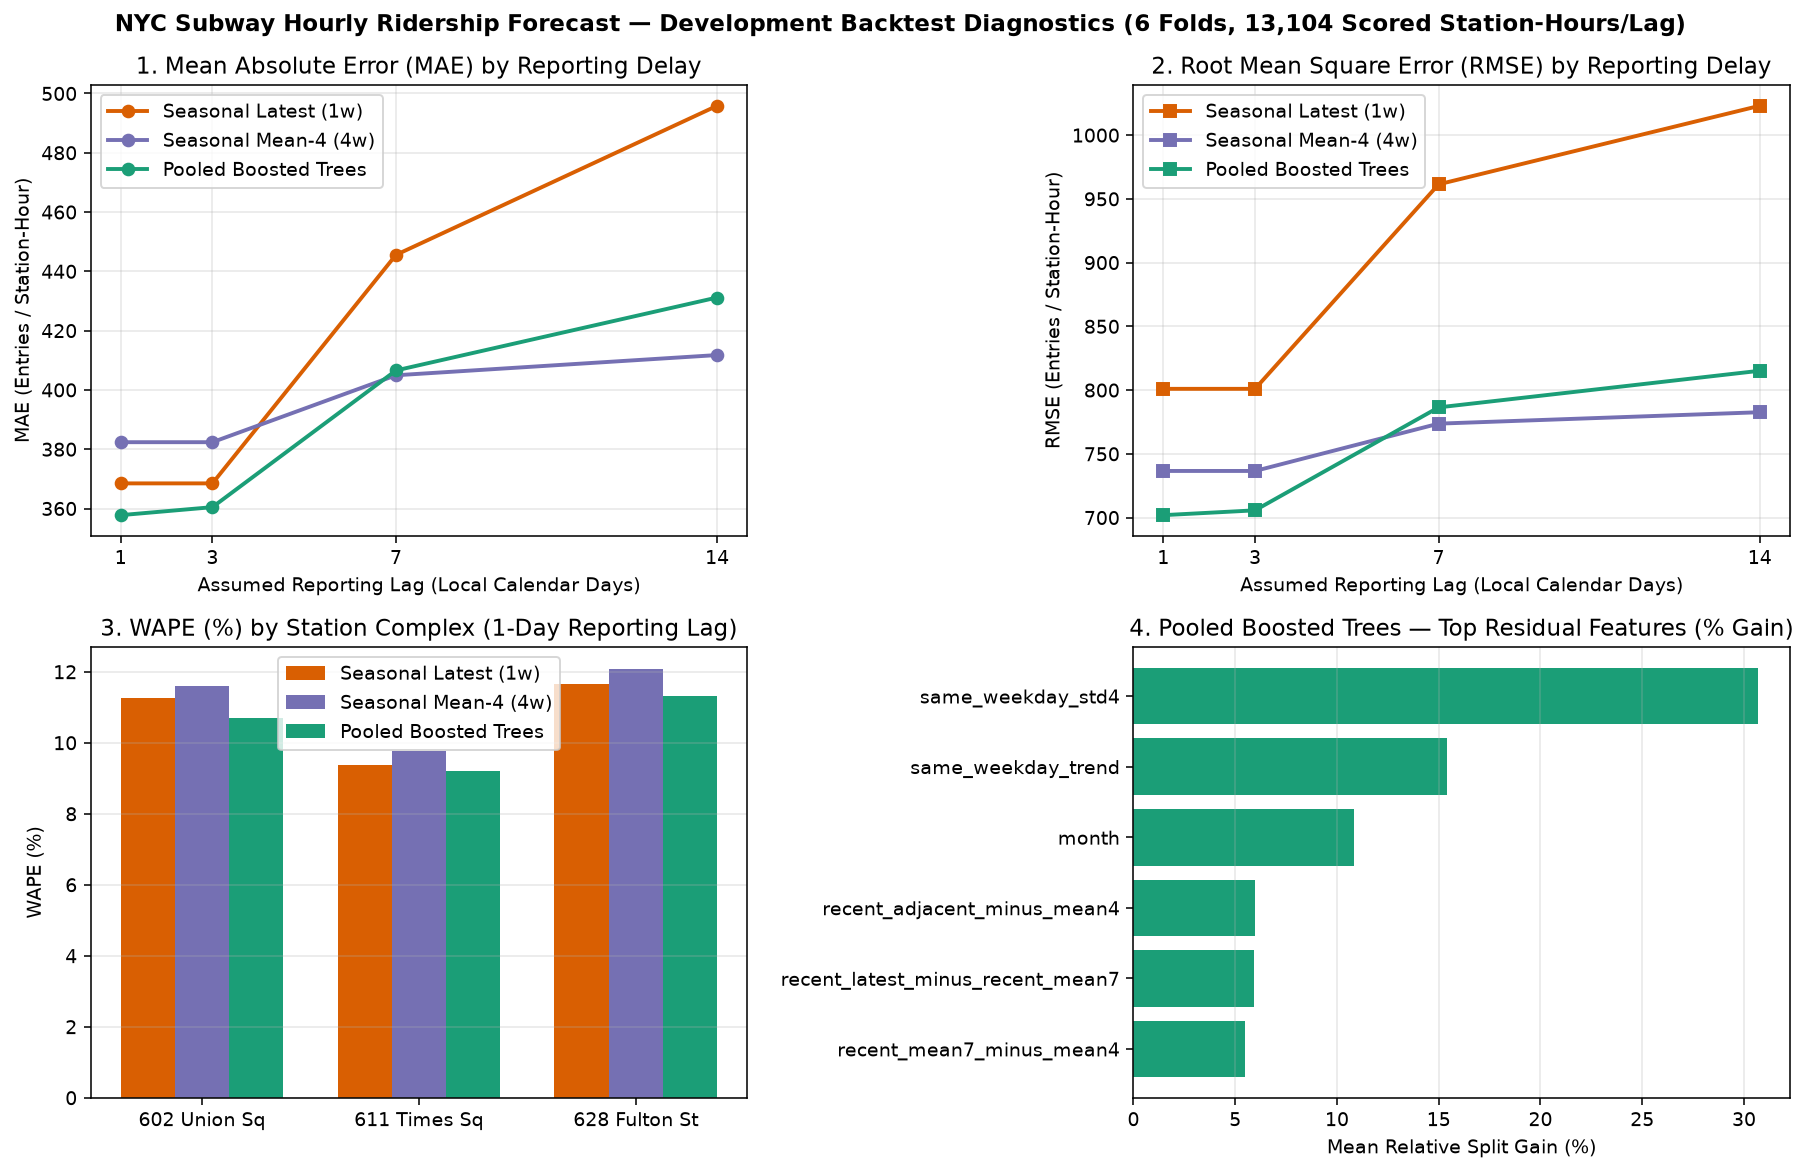

In [6]:
# Cell 6: Generate diagnostic visualizations comparing baselines and pooled boosted trees
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
fig.suptitle("NYC Subway Hourly Ridership Forecast — Development Backtest Diagnostics (6 Folds, 13,104 Scored Station-Hours/Lag)", fontsize=12, fontweight="bold")

methods = ["seasonal_latest", "seasonal_mean4", "pooled_boosted_trees"]
labels = {
    "seasonal_latest": "Seasonal Latest (1w)",
    "seasonal_mean4": "Seasonal Mean-4 (4w)",
    "pooled_boosted_trees": "Pooled Boosted Trees",
}
colors = {
    "seasonal_latest": "#d95f02",
    "seasonal_mean4": "#7570b3",
    "pooled_boosted_trees": "#1b9e77",
}
lags = sorted({r["lag_days"] for r in model_report["overall"]})

# Panel 1: Overall MAE vs. Reporting Lag
ax = axes[0, 0]
for m in methods:
    ys = [next(r["mae"] for r in model_report["overall"] if r["lag_days"] == l and r["method"] == m) for l in lags]
    ax.plot(lags, ys, marker="o", linewidth=2, label=labels[m], color=colors[m])
ax.set_title("1. Mean Absolute Error (MAE) by Reporting Delay")
ax.set_xlabel("Assumed Reporting Lag (Local Calendar Days)")
ax.set_ylabel("MAE (Entries / Station-Hour)")
ax.set_xticks(lags)
ax.grid(True, alpha=0.3)
ax.legend()

# Panel 2: Overall RMSE vs. Reporting Lag
ax = axes[0, 1]
for m in methods:
    ys = [next(r["rmse"] for r in model_report["overall"] if r["lag_days"] == l and r["method"] == m) for l in lags]
    ax.plot(lags, ys, marker="s", linewidth=2, label=labels[m], color=colors[m])
ax.set_title("2. Root Mean Square Error (RMSE) by Reporting Delay")
ax.set_xlabel("Assumed Reporting Lag (Local Calendar Days)")
ax.set_ylabel("RMSE (Entries / Station-Hour)")
ax.set_xticks(lags)
ax.grid(True, alpha=0.3)
ax.legend()

# Panel 3: WAPE (%) by Station Complex at Lag = 1 Day
ax = axes[1, 0]
stations = ["602", "611", "628"]
x_pos = range(len(stations))
width = 0.25
for idx, m in enumerate(methods):
    wapes = [
        next(
            r["wape"] * 100.0
            for r in model_report["by_station"]
            if r["station_complex_id"] == s and r["lag_days"] == 1 and r["method"] == m
        )
        for s in stations
    ]
    offsets = [x + (idx - 1) * width for x in x_pos]
    ax.bar(offsets, wapes, width=width, label=labels[m], color=colors[m])
ax.set_title("3. WAPE (%) by Station Complex (1-Day Reporting Lag)")
ax.set_xticks(list(x_pos))
ax.set_xticklabels(["602 Union Sq", "611 Times Sq", "628 Fulton St"])
ax.set_ylabel("WAPE (%)")
ax.grid(True, axis="y", alpha=0.3)
ax.legend()

# Panel 4: Top Boosted-Tree Residual Split Features (Mean Relative Gain, Lag 1)
ax = axes[1, 1]
f_names = [k for k, _ in reversed(top_gains)]
f_vals = [v * 100.0 for _, v in reversed(top_gains)]
ax.barh(f_names, f_vals, color="#1b9e77")
ax.set_title("4. Pooled Boosted Trees — Top Residual Features (% Gain)")
ax.set_xlabel("Mean Relative Split Gain (%)")
ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()

In [7]:
# Cell 7: Verify exported reproducible report artifact and summary conclusions
exported_path = Path("reports/model_development.json")
exported = json.loads(exported_path.read_text())
assert exported["chronology_violations"] == 0, "chronology violations must be zero"
assert exported["overall"] == model_report["overall"], "exported metrics must match live evaluation"

print("Verified exported artifact:", exported_path)
print("Key empirical findings:")
print("  1. At 1-day and 3-day reporting lags, pooled_boosted_trees achieves the lowest MAE (357.76 and 360.45),")
print("     lowest RMSE (701.89 and 705.67), and lowest WAPE (10.07% and 10.15%), outperforming both seasonal baselines.")
print("  2. At 7-day and 14-day lags, pooled_boosted_trees substantially improves over seasonal_latest (MAE 406.56 vs 445.55")
print("     at lag 7; 431.17 vs 495.85 at lag 14), while the unweighted 4-week average (seasonal_mean4: 404.94 and 411.76)")
print("     is slightly more resilient to the 1-2 week unpublished training-label gap.")

Verified exported artifact: reports/model_development.json
Key empirical findings:
  1. At 1-day and 3-day reporting lags, pooled_boosted_trees achieves the lowest MAE (357.76 and 360.45),
     lowest RMSE (701.89 and 705.67), and lowest WAPE (10.07% and 10.15%), outperforming both seasonal baselines.
  2. At 7-day and 14-day lags, pooled_boosted_trees substantially improves over seasonal_latest (MAE 406.56 vs 445.55
     at lag 7; 431.17 vs 495.85 at lag 14), while the unweighted 4-week average (seasonal_mean4: 404.94 and 411.76)
     is slightly more resilient to the 1-2 week unpublished training-label gap.
